# 40. Imbalanced dataset

In [ ]:
##### The biggest problem in classification analysis is -> Imbalancing of dataset.                   
    
##### Imbalancing dataset: 

means hmare pass jo bhi dataset hai, us dataset ke andr jo bhi hmare category bne hue hai.
us category ke andr koi ek category bhut hi jada bar aa jati hai.

for example: let suppose we are working for a airport company/ air authorised company
wo hmare pass se ek machine learning system bnane chahti hai, means they want to make a AI system.
jiske through wo kisi bhi human ka face detect krke ya face ko read out krke pehchan ske,
ki ye jo person hai, ye indian hai ya ni hai. esa koi wo company system bnane chahti hai.
Ab iske liye unka dataset chahiye hoga. Ab iske liye hme dataset chahiye hoga. to wo company hme kehte hai ki ayegi yha pr 
aur dataset note down kijiye.

AB hmne kya kiya hmne koi bhi ek airport pkda and wha pe jake beth gye.
    ab wha pe jb hm bethte hai to hme pta hai ki ydi hm INDIAN AIRPORT pe bethe hai to
wha pe indian people sbse jada jate hai.
    aur foreign ko jo people hai wo km ate hai.

    ab jb bhi hm apne model bnane chlengee is data ke upr.
        To hme indian peoples ka jo data hai, wo sbse jada dekhne ko milega.

    aur forign people ka jo data hai wo km dekhne ko milega. Isse hoga kya,
isse ye hoga ki jo hmara model hai, wo bias ho jayega.

Bias: bias means jo hmara model hai wo indian data ke upr ya phir hm bat kre ki indian 
data ke jo person ke feature hai, unke upr trained ho jayega. 
    Aur jb bhi hm koi nya data lake denge.
    our model will also represent INDIAN data, ya phir INDIAN PERSON ko hi represent krenge.

This situation is called IMBALANCING DATASET.

In [ ]:
# So, what problem creates from imbalancing data.  (EXPLANATION OF BELOW IMG 9.15.4)

the problem is very simple that hmare jo model hai wo bias ho jata hai,
kisi particular ek hi output ko represent krta hai.

For example: 
let's suppose we have a data of 500 rows.

400 rows, we are training for cat.
100 rows, we are training for dog.

So, when we are going to builing our model?
    Hmare model CAT ke according ho jayega.

    Ab jb hm apne model ko DOG ka data denge, 
    tb bhi model hmara cat ko hi btayega.       

And the reason behind is -> bcoz hmara model bias ho chuka hai, particularly ek data ke upr.



## Technique

    to remove this problem, we use a technique with the help of which 
    we convert a IMBALANCING DATA into BALANACING DATA. 

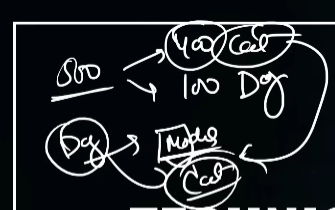
9.15.4

# TECHNIQUES TO HANDLE IMBALANCED DATA

## Random Under Sampling

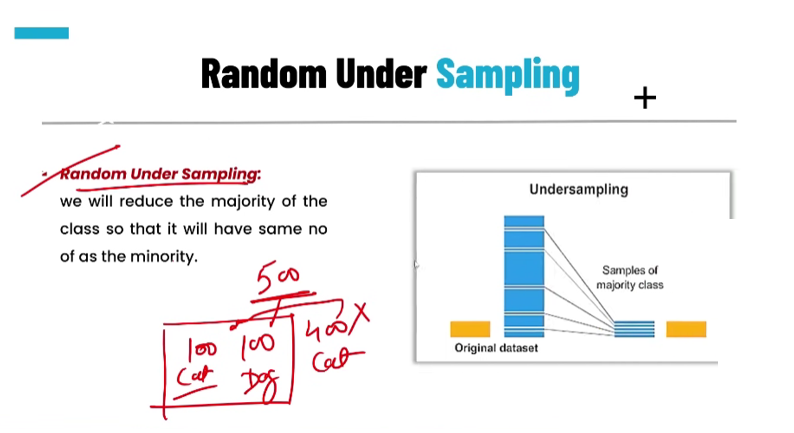
img at 9.16.24

In [ ]:
# Explanation (9.16.24)

jis category ka data large hota hai,
us category ke large dataset me se, randomly hm kuch kuch samples nikalte hai.
aur hmare pass jo lowest data hota hai. Uske equal kr dete hai.

Example:

                    we have 500 data.
                             /\
    100 data represent dog       400 data represent cat

So, what we do in the techniques.
ye jo cat ka data hai. cat ke data me se randomly hm 100 cat ka data nikalenge.

so now, we have 100 random cat data. 
                    500
   -------------------------------
    |                |         |
   100              100     400 x
  Random Cat data   Dog     Cat`
     |               |
     -----------------
             |
          New dataset
      
to hmne yha 100 random cat data get kiya.
    and now hmare pass jo new dataset hoga wo ye hoga.

This techniques is called Random Under Sampling

## Random Over Sampling

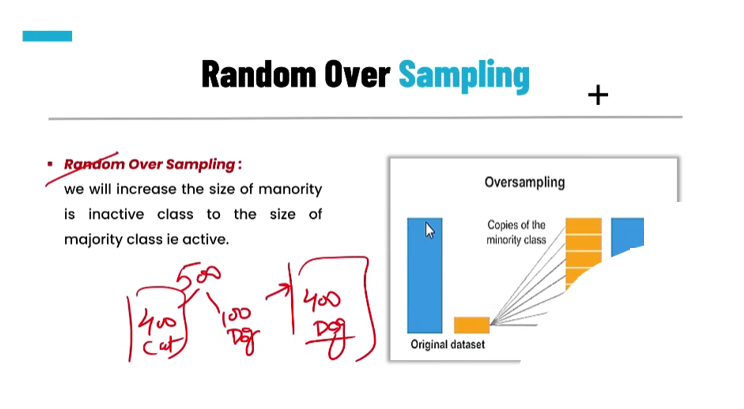
9.17.21

In [2]:
# # Explanation

# In random over sample

# we have 500 data.
#     /\
# 400   100 
# Cat   Dog

# Hm is dog ke data ko repetation kr dete hai. according to this (cat/ majority) data.
#     means hm is Dog ke data ko convert krke 400 Dog ke data ko bdha rhe hai.

# 400 Dog data: ab ye 400 dog ke data ko jo hmne bnaya yha pe.
#     isi ki duplicacy chlti rhegi. means 100, 100, 100, 100 ke hmne 4 package bna diye.
#         that is a 400 data.

#     And in this 400 cat and 400 dog wala data hmara pass same balance me aa jata hai.
#     So, this technique is Randome Over Sampling.

# So, with the help of Imbalancing techniques. we can remove the Imbalancing from our data.

## Practical

### Dataset Overview

In [ ]:
# Dataset we will use.

# SocialMedia Network. We have work on this dataset before as well.

# Age	EstimatedSalary	Purchased
# 19	19000	0
# 35	20000	0
# 26	43000	0

# this is the data about the any person on the basis on Age and Estimated Salary
# has Purchased social media network or not.

# just like we can assume that a person has purchased the Netflix subscription or not,
# amazon prime subcription purchased or not. usse relalted ye data hai.

### Problem in the dataset

In [157]:
# Now the output in this dataset which is Purchased.
# This is imbalance.

### Codes

In [158]:
import pandas as pd

In [159]:
dataset = pd.read_csv(r"C:\Users\ATVIK SHARMA\OneDrive\DataSets\Social_Network_Ads.csv")

In [160]:
# // video me pehle se bs 3 hi column hai, so i am dropping these columns
dataset.drop(columns=["User ID", "Gender"],inplace=True)

In [161]:
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [162]:
dataset.columns

Index(['Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [163]:
# //errors='ignore
# dataset.drop(["User ID", "Gender"], inplace=True, errors='ignore)

In [164]:
### Checking balancing

# Now we will to Purchased that it has balancing or not.

In [165]:
dataset["Purchased"].value_counts()


# Explanation
# ----------------

# value_counts() function will count category wise

# 0    257
# 1    143
# it means imbalancing in data

# now, when we create our model here,
# then hmara model 0 ke according bn jayega.
# means 0 ke upr balance ho jayega.
# ab jb bhi hm isme koi bhi input denge.
# then ye hme hmesha 0 answer dega.
# Not hmesha but most of the cases me it will give us 0 answer.

# Very less cases ke andr 1 answer dega.

Purchased
0    257
1    143
Name: count, dtype: int64

In [166]:
# Now, we will create model on it.
# and then we will check accuracy on it.

In [167]:
# Separating

x = dataset.iloc[:,:-1]
y = dataset["Purchased"]

In [168]:
from sklearn.model_selection import train_test_split

In [169]:
x_train, x_test, y_train, y_test = train_test_split(x,y,random_state=42,test_size=0.2)

# //test_size = 0.2 -> 20%

In [170]:
# Now we will apply model
# to model ke liye hm simple logistic lgane wale hahi.

In [171]:
from sklearn.linear_model import LogisticRegression

In [172]:
lr = LogisticRegression()
lr.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [173]:
lr.score(x_test,y_test)*100

88.75

In [174]:
# Now, we will check ki isme bias ho rha hai ya ni.

In [175]:
lr.predict([[19,19000]])  # <-- x should be in 2d

19	19000	0

19, 19000 -> zero bhi hai.
    and our model is also giving 0 answer.
        so this is good.

SyntaxError: invalid syntax (1002518015.py, line 3)

In [176]:
# now 1 ke cases me check krenge.

lr.predict([[45,26000]])


# Observation
# ------------------

# the answer in dataset is 1 at 45, 26000
# but our Model prediction here is 0

# Reason
# --------------

# why our model is giving 0 when the answer is 1 at [45,2600] value.
#     Because our data is imbalancing here.

#     Here zero has been dominating.

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [177]:
46  28000 1
lr.predict([[46,28000]])

# answer is 1 in dataset. but again our model is giving 0.

# It means hmara jo model bna hai yha pe, wo bias ho chuka hai.
#     It is representing 0 in every category.

# It means most of the answers hme yha pe 0 hi milne wale hai.

SyntaxError: invalid syntax (402201718.py, line 1)

### imblearn

In [178]:
# Balancing using imblearn module

In [179]:
### Now, we will Removing biasness by doing balancing

# for balancing we can use 2 techniques.
#     1. Random Under Sampling
#     2. Random Over Sampling

# for imbalancing we require a module -> Imblearn module
# with the help of our dataset is balancing.

In [180]:
# Installation (imblearn module)
# -------------------------------------

# search "imblearn" -> Python official website "PyPI" -> copy "pip install imblearn"
# paste on cmd and download

In [181]:
import pandas as pd

In [182]:
dataset = pd.read_csv(r"C:\Users\ATVIK SHARMA\OneDrive\DataSets\Social_Network_Ads.csv")

In [183]:
# // video me pehle se bs 3 hi column hai, so i am dropping these columns
dataset.drop(columns=["User ID", "Gender"],inplace=True)

In [184]:
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [185]:
x = dataset.iloc[:,:-1]
y = dataset["Purchased"]

In [186]:
dataset["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [187]:
from imblearn.under_sampling import RandomUnderSampler


# imblearn me jane ke badh we have to choose a sampling
# there are 2 samping here:
# under sampling
# over sampling


# Over sampling: low data ko higher data me convert krte hai.
# Under sampling: High data ko low me convert krte hai.


# Here we will first use/ call -> under_sampling 

In [188]:
ru = RandomUnderSampler()
ru_x, ru_y =  ru.fit_resample(x,y)

# RandomUnderSampling is class, jiska hmne yha ek object bnaya hai.

In [189]:
# Now, we will sampling of our dataset.

#     to iske liye pehle hm apna dataset ko input & output me alg alg kr lete hai.

In [190]:
ru_x

# age and estimatedsalary is x me as it milega hme


# Note: jitne bar hm is code ko run krenge,
# utne bar ye values change hogi.
    # bcoz resample data ko khi se bhi le rha hai

,Age,EstimatedSalary
325,41,60000
1,35,20000
181,31,71000
193,19,70000
102,32,86000
...,...,...
393,60,42000
395,46,41000
396,51,23000
397,50,20000


In [191]:
ru_y

# y me purchased hai

325    0
1      0
181    0
193    0
102    0
      ..
393    1
395    1
396    1
397    1
399    1
Name: Purchased, Length: 286, dtype: int64

In [192]:
# Now, we will check that kya hmara data sample hua ya ni hua.
# so here we have used undersampling.
# and undersampling large data ko low me convert krta hai.

# means here purchased column imbalancing tha.
    # to hm ise dubara check krenge.

ru_y.value_counts()

# yes, our purchased column has been balanced now
# with the help of RANDOM UNDER SAMPLING.

Purchased
0    143
1    143
Name: count, dtype: int64

In [193]:
# Now, balancing krne se hmare pass new x and y aye hai.
# which is ru_x, ru_y

# Now, we will create model on it.
# and then we will check its accuracy and result.

# so here we will apply model on balancing data.
    # and upr hmne normal data pe apply kiya tha.
    # then we will compare and check accuray

In [194]:
from sklearn.model_selection import train_test_split

In [195]:
x_train, x_test, y_train, y_test = train_test_split(ru_x,ru_y,random_state=42,test_size=0.2)

# x and y resample wala ho is bar

In [196]:
from sklearn.linear_model import LogisticRegression

In [197]:
lr = LogisticRegression()
lr.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [198]:
lr.score(x_test,y_test)*100

# score less aya hai is bar

81.03448275862068

In [199]:
lr.predict([[19,19000]])

# right prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [200]:
lr.predict([[46,28000]])

# wrong prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [201]:
lr.predict([[46,26000]])

# wrong prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [202]:
lr.predict([[45,26000]])

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [203]:
# //
lr.predict([[46,41000]])
      
# right

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [204]:
lr.predict([[49,36000]])

# right prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [205]:
# so, yha pe accuracy km aye hai, but hmara model yha pe bias nhi hua hai.
#     bcoz hmara model yha pe balance ho chuka hai.
#     without balancing me hr bar 0 hi predict kr rha tha.
#     but is bar 1 bhi predict kr rha hai.

### RandomOverSampling

In [206]:
from imblearn.over_sampling import RandomOverSampler

In [207]:
ro = RandomOverSampler()
ro_x, ro_y = ro.fit_resample(x,y)


# ro gives us 2 data, 
# one is x and 2nd is y

In [208]:
# Oversampling me kya hota hai?

# jo data km hai, wo apne ap ko repeat krta hai,
# aur jo data jada hai, us data ke brar kr leta hai.
# That is called of random over sample

In [209]:
ro_y.value_counts()

Purchased
0    257
1    257
Name: count, dtype: int64

### Creating Model

In [212]:
x_train1, x_test1, y_train1, y_test1 = train_test_split(ro_x,ro_y,random_state=42,test_size=0.2)

In [213]:
lr1 = LogisticRegression()
lr1.fit(x_train1,y_train1)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [216]:
# checking score
lr1.score(x_test1,y_test1)

0.8155339805825242

In [217]:
lr1.predict([[19,19000]])

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [218]:
lr1.predict([[45,26000]])

# wrong prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [219]:
lr1.predict([[45,28000]])

# wrong prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [222]:
lr1.predict([[51,23000]])

# right prediction

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [223]:
# To kafi ese situation hoti hai,
# jha pe hme dataset ko balancing krne ki jrurt pdti hai,
# to wha pr random under sample, or random over sample ka istemal 
# krte hue, hm dataset ko balancing kr skte hai.
#     aur apne accuracy ko improve kr bhi skte hai,
# yha phir apne model ko improve kr skte hai.


# Note: something accuracy km bhi aa rha hai balancing apply krne se.
#     but hmara jo result aa rha hai, means prediction 
# wo normal data/ without balancing data se better hota hai

# 41. Naive Bayes

### In today's video

In [224]:
# How Does The Naive Bayes Algorithm Works?

# In today's video we will understand about naive bayes algorith.

# and we will understand that iske andr NAIVE KYA HAIand what is BAYES.

In [225]:
# ### Explanation (what is naive bayes algorith)

# jb hm classification algorithm pdhte hai, to us classification algorithm ke andr
# naive bayes algorithm ati hai, aur ye purily classification algorithms hai,
# joki probablitic basis pe kam krti hai,

# ye algorithm probability basis ke andr ye condition basis pe kam krti hai,
# condition probability example: hme movie dekhne jana hai, and bahar mosam shi nhi hai,
# mtlb badal aye hue hai, then I will say that
# if Rain -> then I will not go to watch movie.
# if no rain -> then i will go to watch movie.

# so, here we have applied a condition to going to watching movie.
#     the condition is Rain or No Rain.

# so, basically that is a probability.
#     mtlb hm is cheez ki probability nikalte hai, this is called conditional probability.



# Isi ke upr naive bayes algorithm apply hoti hai. aur iske upr working chlti hai.
# Now, let's discuss how naive bayes algorith works.

# NAIVE BAYES

* Navie Bayes is a classification algorithm based on Bayes' theorem.
* Which is a probability theory that describes the probability of an event, based on prior 
knowledge of conditions that might be related to the event.

<br>
<br>

* <span style="color:red">Naive :</span> It is called Naive because it assumes that the occurence of a certain
feature is independent of the occurence of other features.

* <span style="color:red">Bayes :</span> It is called Bayes because it depends on the principle of Bayes' Theorem.

In [228]:
## Explanation:


             # Naive Bayes Algorith
# Naive bayes algorithm is a classification algorithm.
#     or we can say that purely classification.
#     logistic and naive bayes only works on classificaition.

# And, basically it works on conditional probability only.


               # Naive: 
# Naive means feature.
# means dataset ke andr hmne jo bhi feature de rkhe hai.

              # Bayes: 
# This is bayes theory. naive ke andr apply hota hai. 
# ab ye bayes theorem hoti kaise hai, kaise ate hai.
# we will discuss in detail.

### CONDITIONAL PROBABILITY

In [ ]:
# First we will understand probability little bit.
# And probability se phir hm naive bayes theorem ke upr jayenge.



### Probabitlity
# probability means smbhabna or assumption

## Probability Formulation
P(E) = F.O.
      -------
       T.O.

           
P(E) = Probability of an event
P(F.O) = Favourable outcome
P(T.O) = Total outcome

In [ ]:
## Ex 1:

# we have a bag. and hm isme hath dalenge then what will be the chance to get 
# red ball. 
    
# to yha pe hm jo chances ki bat kr rhe hai, that is a probability.

# So, we have to find the probability of getting red ball.

# ----------------------------------------------------------------------------

### Favourable outcome
# red ball is our favourable outcome.
# Favourable outcome means jo hm chahte hai,
# hm us cheez ki hm probability nikalna chate hai.
# --------------------------------------------------------------------------------

# Solution: No. of R = 3
#           No. or B = 2
#           P(R) = 3/5

# This is probability

In [ ]:
# Ex 2: 

Rolling a die and find the probability of getting 6.
    means 6 ane ke kitne chance hai.


solution:
Event = {1,2,3,4,5,6}
Favourable outcome: 1 (means hm kya chate hai, hm 6 chahte hai, means ek favourable outcome)
Total outcome: 6

P(getting 6) = 1/6


# Event: dies ko roll krne pr kon kon se event hote hai.
# events means jb hm dies ko roll krte hai, to kya kya cheeze hme dikhaye dete hai, that is our event.

### Probability value lie between 0 and 1

0 <= P(E) <=1

It can be 0 and 1 as well.

In [229]:
# to do this part  and the above probability screenshot taking

# Naive Bayes (PRACTICAL)

In [230]:
# In this video we will apply naive bayes algorithm practically on a dataset.
    # and also we will see that how to make DECISION REGION.

### Dataset we will use

In [232]:
# placement.csv

# We have to predict whether a person got placed or not based on their CGPA or score.

# cgpa/ annual score 

### Importing required libraries

In [234]:
import pandas as pd # to load dataset
import matplotlib.pyplot as plt  # to make graphs
import seaborn as sns  # to make advance graphs
from mlxtend.plotting import plot_decision_regions  # to make decision region

In [235]:
dataset = pd.read_csv(r"C:\Users\ATVIK SHARMA\OneDrive\DataSets\placement.csv")

# //r for raw string. so that the back slashes treated as literal characters.

In [236]:
dataset.head(3)

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1


In [ ]:
# Now we will create distribution plot.

# so that we can check that it is normal distribution or not.
# we will create ke plot.

# we will create kde plot to check the normal distribution.

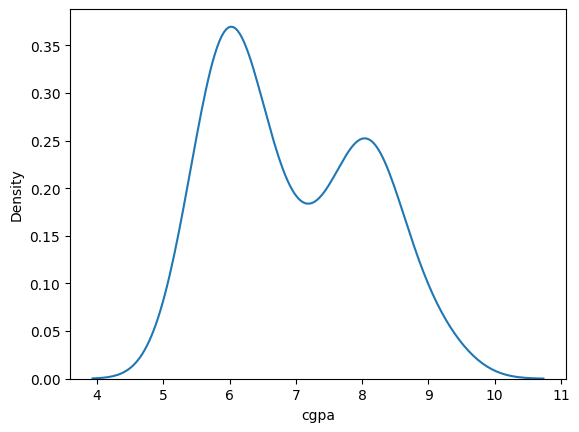

In [247]:
sns.kdeplot(data=dataset["cgpa"])
plt.show()

# It is not showing almost normal distribution. it's ok.
# bcoz ye skewed curve bhi ni hai.

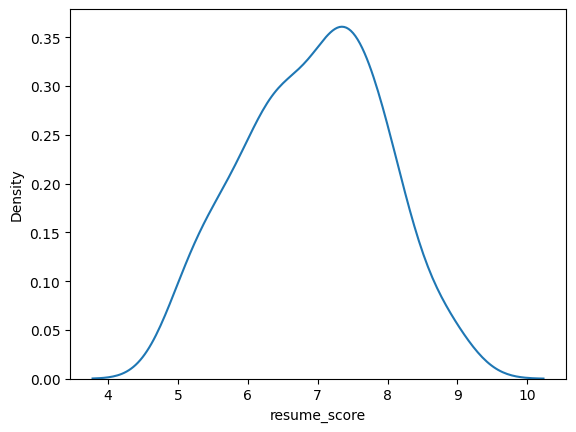

In [249]:
sns.kdeplot(data=dataset["resume_score"])
plt.show()

# score is seemed normal distribution

In [250]:
# Observation

# score normal dist. lg rha hai.
# but thoda cgpa sa ni lg rha 

# ok, so hme yha pe thodda sa idea ho gya hai ki jo hmara graph hai,
# curvature hai, wo kis treh se dikh rhe hai yha pe.


# So, basically hmne last class me smjha tha ki,
# we will apply model on the basis of our data,

# for ex:
# i) Gaussian NB: When our data is normal distribution.
# ii) Bernoulli NB: When our data with binary features. 
# iii) Multinomial: When our data is texual data or discrete data.

In [237]:
dataset.isnull().sum()

cgpa            0
resume_score    0
placed          0
dtype: int64

In [238]:
# Need to scaling here.
# No need to scaling, hme itne required nhi lg rhe hai.

In [239]:
# Checking separability
# --------------------------

# we will create a graph to check its separability that it is 
# linearly separable or non-linearly separable.

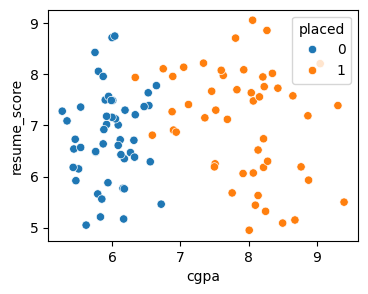

In [243]:
plt.figure(figsize=(4, 3))
sns.scatterplot(x="cgpa",y="resume_score",data=dataset,hue="placed")
plt.show()

# our data is linearly separable
# and kuch orange and blue data ache se separable nhi hai.
    # so, yha pe kuch kuch mis-classification hone wala hai.
# We can see here.

In [244]:
# Separating data into input and output.
# means dependent or independent feature ke andr alg alg krte hai.

x = dataset.iloc[:,:-1]
y = dataset["placed"]

In [245]:
from sklearn.model_selection import train_test_split

In [246]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [252]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB

In [254]:
# Now, we know that ki yha pe GaussianNB lgne wala hai,
# but we will all 3 and try.

In [255]:
gnb = GaussianNB()
gnb.fit(x_train,y_train)

,priors,None
,var_smoothing,1e-09


In [258]:
# checking accuracy
gnb.score(x_test,y_test)*100, gnb.score(x_train,y_train)*100

# This is a very good accuracy

(100.0, 97.5)

In [270]:
gnb.predict([[6.17,5.17]])  # 6.17	5.17	0

# //We have taken 2nd row data for prediction

# array([0]): prediction is correct
# to isne kafi acha prediction krke diya hai yha pe.

# In this way we can do prediction.

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


array([0])

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


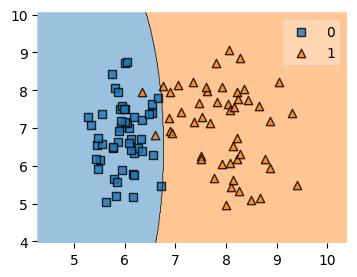

In [266]:
# Now, we will create decision region to check that
# who is splitting better

plt.figure(figsize=(4,3))
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=gnb)
plt.show()

# clf means classifier

# read: plt.show() --> show function ko show krenge.



# Graph observation
# ----------------------

# GaussianNb ne almost shi treke se prediction krne ki kosis ki hai,
# aur bhut hi perfect cut nikala hai, yha pe.
#     aur ek, do mis-classification hai,
# but bhut acha prediction krke diya hai yha pe.

In [259]:
mnb = MultinomialNB()
mnb.fit(x_train,y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [260]:
mnb.score(x_train,y_train)*100, mnb.score(x_test,y_test)*100

# poor accuracy as compare to previous
# bcoz we know that multinomial gives better accuracy on text.

(73.75, 75.0)

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(


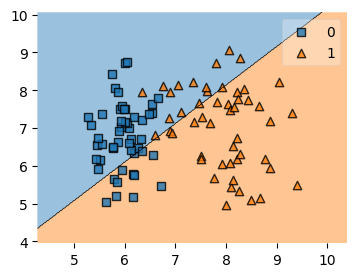

In [267]:
plt.figure(figsize=(4,3))
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=mnb)
plt.show()

# Multinomial NB ne ek perfect line bnaya hai,
# but ye line itne ache se nhi bna hai,
# we can not say it a perfect link. 
# thik hai, mnb ne ek line bnake diya hai yha pe,
# bcoz isne bhut jada mis-classification kiya hai yha pe.

# So, it is not working perfectly.

In [261]:
bnb = BernoulliNB()
bnb.fit(x_train,y_train)

# when bernoulliNB gives better answer.
#     when the input feature is in 0 and 1.

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [262]:
bnb.score(x_train,y_train)*100, bnb.score(x_test,y_test)*100

# This is very bad accuracy as compare to these 3.

(50.0, 50.0)

C:\Users\ATVIK SHARMA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but BernoulliNB was fitted with feature names
  warnings.warn(


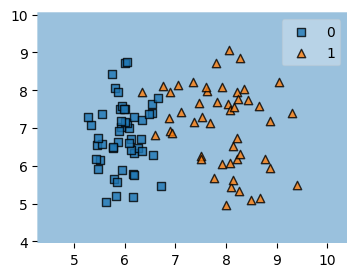

In [268]:
plt.figure(figsize=(4,3))
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=bnb)
plt.show()


# To bnb me to decision region hi nhi rha.
# kuki 50, 50 chances hai, yha pe.

# It means decision region bhi perfectly nhi bn paya yha pe.

In [272]:
# # So, in this way we can try in our dataset 
# # that Which algorithm we have to apply in Naive Bayes.

# jaise hme dataset ko dekhke pta chl rha tha ki,
# our dataset is normal distribution.

# ydi hm ise aur ache se normal distribution krte like cgpa normal distribution ni hai,
# lekin ydi hm FUNCTION TRANSFORMATION lga ke isko aur ache se NORMAL DISTRIBUTION bnate,
# to ye accuracy aur jada ache bn jate,

# aur ye jo curvature hai, wo aur jada perfect curvature ki trf chla jata gnb me. right.

# baki multi-nomial: text ke upr acha answer deta hai,

# And if we talk about Bernoulli: then it gives perfect answer on binary input feature like 0,1 ke andr answer.

In [271]:
# So, here we have understand that how we can apply Naive Bayes Algorithm.

#     kiske liye?
#     for future prediction.

In [ ]:
# So, now we have understand that how these 3 algorithm works.